# AeroCast
## Multi-Pollutant Air Quality Forecasting & Analysis

## 1. Project Overview

AeroCast uses **42 pretrained XGBoost regression models** to forecast **7 pollutants** (PM2.5, PM10, NO2, SO2, CO, O3, NH3) at **6 future horizons** (+1 h, +6 h, +12 h, +24 h, +48 h, +72 h) for a chosen monitoring station.

The forecasts are analysed to understand **future pollutant concentrations, future AQI, the dominant pollutant and increasing/decreasing trends**.

## 2. Environment & Configuration

All paths, names and settings live in this one cell.

In [1]:
import json
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ---------------------------------------------------------------- paths
PROJECT_ROOT = Path("..")
if not (PROJECT_ROOT / "data").exists() and Path("data").exists():
    PROJECT_ROOT = Path(".")                       # launched from the project root instead
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "PM25_MASTER_CPCB_ERA5_2021_2025.parquet"
MODEL_DIR = PROJECT_ROOT / "models"                # read-only: models are only ever loaded
EVALUATION_DIR = PROJECT_ROOT / "evaluation"
FIGURE_DIR = EVALUATION_DIR / "figures"
for _d in (EVALUATION_DIR, FIGURE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- schema
TIME_COL = "Timestamp"
ID_COL = "Station ID"
NAME_COL = "Station Name"

POLLUTANTS = {                                      # model key -> dataset column
    "PM25": "PM2.5 (µg/m³)",
    "PM10": "PM10 (µg/m³)",
    "NO2": "NO2 (µg/m³)",
    "SO2": "SO2 (µg/m³)",
    "CO": "CO (mg/m³)",
    "O3": "Ozone (µg/m³)",
    "NH3": "NH3 (µg/m³)",
}
POLLUTANT_LABEL = {"PM25": "PM2.5", "PM10": "PM10", "NO2": "NO2", "SO2": "SO2", "CO": "CO", "O3": "O3", "NH3": "NH3"}
LABEL_TO_KEY = {v: k for k, v in POLLUTANT_LABEL.items()}
POLLUTANT_UNIT = {k: re.search(r"\((.*?)\)", c).group(1) for k, c in POLLUTANTS.items()}
HORIZONS = [1, 6, 12, 24, 48, 72]
EXPECTED_MODEL_COUNT = 42

# ---------------------------------------------------------------- settings
MODEL_NAME_HINT = None          # only needed if models/ holds two files for the same pollutant+horizon,
                                # e.g. "CPCB_ERA5" to prefer files whose name contains that text
MIN_FEATURE_COVERAGE = 0.80     # a forecast origin needs >= 80 % of the model inputs to be non-null
TREND_TOLERANCE_PCT = 5.0       # |change| below this % counts as "Approximately stable"
DOWNCAST_FLOAT32 = True         # keep the in-memory table small; XGBoost works in float32 internally anyway
VERIFY_SAMPLE_PER_FAMILY = 2    # how many stored columns per feature family are re-computed and compared

RUN_HISTORICAL_COMPARISON = True   # Appendix A (inference only, never trains)
HELD_OUT_START = "2025-01-01"      # start of the historical comparison window (UTC)
EVAL_STRIDE_HOURS = 6              # use every 6th hour as a forecast origin in Appendix A

assert len(POLLUTANTS) * len(HORIZONS) == EXPECTED_MODEL_COUNT == 42
print(f"xgboost {xgb.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Data  : {DATA_PATH}")
print(f"Models: {MODEL_DIR}  (read-only)")
print(f"Output: {EVALUATION_DIR}")

xgboost 3.2.0 | pandas 3.0.6 | numpy 2.4.6
Data  : ..\data\processed\PM25_MASTER_CPCB_ERA5_2021_2025.parquet
Models: ..\models  (read-only)
Output: ..\evaluation


## 3. Load Cleaned Parquet Dataset

The dataset is read with `pd.read_parquet` and sorted by **`Station ID`, then `Timestamp`**. Every lag/rolling operation in this project is *station-wise*, which only makes sense on data ordered station-by-station in time. `Timestamp` is parsed as timezone-aware UTC.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Expected AeroCast/data/processed/PM25_MASTER_CPCB_ERA5_2021_2025.parquet "
        "with this notebook inside AeroCast/notebooks/."
    )

df = pd.read_parquet(DATA_PATH)
for required in (TIME_COL, ID_COL):
    assert required in df.columns, f'Column "{required}" not found. First columns: {list(df.columns)[:12]}'
assert df.columns.is_unique, "Dataset contains duplicate column names"

df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce", utc=True)
df = df.sort_values([ID_COL, TIME_COL]).reset_index(drop=True)

if DOWNCAST_FLOAT32:                                  # dtype only; values unchanged to float32 precision
    f64 = df.select_dtypes("float64").columns
    df[f64] = df[f64].astype("float32")

print("Dataset loaded")
print(f"  Rows       : {len(df):,}")
print(f"  Columns    : {df.shape[1]:,}")
print(f"  Date range : {df[TIME_COL].min()}  ->  {df[TIME_COL].max()}")
print(f"  Stations   : {df[ID_COL].nunique()}")
print(f"  Memory     : {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

missing_pollutants = {k: c for k, c in POLLUTANTS.items() if c not in df.columns}
if missing_pollutants:
    raise ValueError(f"Pollutant column(s) not in dataset: {missing_pollutants}")

availability = pd.DataFrame({
    "Pollutant": [POLLUTANT_LABEL[k] for k in POLLUTANTS],
    "Column": list(POLLUTANTS.values()),
    "Available %": [round(df[c].notna().mean() * 100, 2) for c in POLLUTANTS.values()],
    "Min": [df[c].min() for c in POLLUTANTS.values()],
    "Mean": [df[c].mean() for c in POLLUTANTS.values()],
    "Max": [df[c].max() for c in POLLUTANTS.values()],
}).round(2)
display(availability)

Dataset loaded
  Rows       : 657,360
  Columns    : 142
  Date range : 2021-01-01 00:00:00+00:00  ->  2025-12-31 23:00:00+00:00
  Stations   : 15
  Memory     : 0.38 GB


,Pollutant,Column,Available %,Min,Mean,Max
0,PM2.5,PM2.5 (µg/m³),96.01,1.0,107.940002,995.000000
1,PM10,PM10 (µg/m³),95.86,1.0,217.990005,1000.000000
2,NO2,NO2 (µg/m³),93.90,0.1,38.599998,420.450012
3,SO2,SO2 (µg/m³),93.37,0.1,10.680000,197.600006
4,CO,CO (mg/m³),92.18,0.0,1.280000,9.880000
5,O3,Ozone (µg/m³),91.80,0.1,35.250000,472.000000
6,NH3,NH3 (µg/m³),93.61,0.1,39.990002,389.029999


## 4. Dataset Validation

A light check of what the pipeline depends on. The dataset is already cleaned, so this is a sanity check rather than a data-cleaning study. Hourly continuity is measured **per station** (`groupby("Station ID")["Timestamp"].diff()`), never across the whole table.

In [3]:
HOUR = pd.Timedelta(hours=1)

n_nat = int(df[TIME_COL].isna().sum())
n_dup = int(df.duplicated([ID_COL, TIME_COL]).sum())
step = df.groupby(ID_COL, sort=False)[TIME_COL].diff().dropna()
pct_hourly = float((step == HOUR).mean() * 100)
n_gaps = int((step != HOUR).sum())

checks = pd.DataFrame([
    ("Shape", f"{df.shape[0]:,} rows x {df.shape[1]} columns", "OK"),
    ("Date range", f"{df[TIME_COL].min():%Y-%m-%d} -> {df[TIME_COL].max():%Y-%m-%d}", "OK"),
    ("Stations", str(df[ID_COL].nunique()), "OK"),
    ("Unparseable timestamps", f"{n_nat:,}", "OK" if n_nat == 0 else "WARN"),
    ("Duplicate (Station ID, Timestamp)", f"{n_dup:,}", "OK" if n_dup == 0 else "WARN"),
    ("Station-wise steps that are exactly 1 h", f"{pct_hourly:.3f}%", "OK" if n_gaps == 0 else "WARN"),
    ("Non-hourly steps / gaps", f"{n_gaps:,}", "OK" if n_gaps == 0 else "WARN"),
    ("Pollutant columns present", f"{len(POLLUTANTS)} / {len(POLLUTANTS)}", "OK"),
], columns=["Check", "Result", "Status"])
display(checks)

key_missing = (df[[c for c in POLLUTANTS.values()]].isna().mean() * 100).round(2).rename("Missing %").to_frame()
print("Missing values in the pollutant columns:")
display(key_missing)
overall = df.isna().mean().sort_values(ascending=False) * 100
print("Columns with the most missing values (top 8):")
display(overall.head(8).round(2).rename("Missing %").to_frame())

if n_dup or n_gaps:
    print("NOTE: duplicates/gaps exist. Stored features are used as-is (they were built on the original row order); "
          "in Section 6 a lag/rolling re-computation is compared with the stored columns to confirm they agree.")
else:
    print("Data is complete hourly data per station: one row per hour, so a row shift equals an hour shift.")

,Check,Result,Status
0,Shape,"657,360 rows x 142 columns",OK
1,Date range,2021-01-01 -> 2025-12-31,OK
2,Stations,15,OK
3,Unparseable timestamps,0,OK
4,"Duplicate (Station ID, Timestamp)",0,OK
5,Station-wise steps that are exactly 1 h,100.000%,OK
6,Non-hourly steps / gaps,0,OK
7,Pollutant columns present,7 / 7,OK


Missing values in the pollutant columns:


,Missing %
PM2.5 (µg/m³),3.99
PM10 (µg/m³),4.14
NO2 (µg/m³),6.10
SO2 (µg/m³),6.63
CO (mg/m³),7.82
Ozone (µg/m³),8.20
NH3 (µg/m³),6.39


Columns with the most missing values (top 8):


,Missing %
Benzene (µg/m³),17.38
RF (mm),8.72
Ozone (µg/m³),8.20
CO (mg/m³),7.82
SO2 (µg/m³),6.63
NH3 (µg/m³),6.39
NO2_x_ERA5_BLH,6.10
NO2 (µg/m³),6.10


Data is complete hourly data per station: one row per hour, so a row shift equals an hour shift.


## 5. Inspect Available Stations & Choose What to Forecast

Pick a **station** and (optionally) a **forecast origin**, the moment from which the next 72 hours are predicted. Edit the two variables below.

* `STATION_ID = None` → the first station with enough data is chosen automatically.
* `FORECAST_TIME = None` → the latest hour whose model inputs are sufficiently complete is used. A value such as `"2025-06-15 08:00"` (UTC) forecasts from that hour instead, which is handy for comparing against what actually happened (Appendix A).

In [4]:
# ======================== USER SELECTION (edit these) ========================
STATION_ID = None        # e.g. "site_5024"  -> None = automatically use the first valid station
FORECAST_TIME = None     # e.g. "2025-06-15 08:00" (UTC) -> None = latest origin with sufficient valid features
# =============================================================================

grp = df.groupby(ID_COL, sort=True)
station_table = pd.DataFrame({"Rows": grp.size(), "Start": grp[TIME_COL].min(), "End": grp[TIME_COL].max()})
if NAME_COL in df.columns:
    station_table.insert(0, "Station Name", grp[NAME_COL].first())
cover = (df[list(POLLUTANTS.values())].notna().groupby(df[ID_COL]).mean() * 100).round(1)
cover.columns = [f"{POLLUTANT_LABEL[k]} %" for k in POLLUTANTS]
station_table = station_table.join(cover)
display(station_table)

if STATION_ID is None:
    ok = station_table[(station_table["Rows"] >= 24 * 30) & (cover >= 50).all(axis=1)]
    if ok.empty:
        print("WARNING: no station has >= 50 % coverage for every pollutant; using the first station.")
        ok = station_table
    STATION_ID = ok.index[0]
    print(f"STATION_ID not set -> automatically using the first valid station: {STATION_ID!r}")
assert STATION_ID in station_table.index, f"STATION_ID {STATION_ID!r} not found. Choose one of: {list(station_table.index)}"

STATION_NAME = station_table.loc[STATION_ID, "Station Name"] if "Station Name" in station_table.columns else str(STATION_ID)
station_pos = np.flatnonzero((df[ID_COL] == STATION_ID).to_numpy())     # row positions of this station
print(f"\nSelected station: {STATION_ID} - {STATION_NAME}   ({len(station_pos):,} rows)")
print(f"Forecast origin : {'latest valid hour (automatic)' if FORECAST_TIME is None else FORECAST_TIME}")

,Rows,Start,End,PM2.5 %,PM10 %,NO2 %,SO2 %,CO %,O3 %,NH3 %
Station ID,,,,,,,,,,
site_124,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,94.0,94.1,94.9,89.8,88.8,92.8,95.7
site_1420,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,94.5,94.6,93.9,93.6,90.3,93.6,92.4
site_1421,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,97.2,97.2,94.8,94.5,93.8,92.3,94.4
site_1422,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,97.7,96.7,94.1,93.1,92.4,93.5,94.0
site_1425,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,96.2,95.9,97.4,97.1,93.2,91.3,95.3
site_1426,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,94.3,94.0,91.4,90.4,89.7,90.3,91.2
site_1428,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,97.5,96.9,94.1,94.5,92.1,92.8,92.5
site_1429,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,96.5,97.3,91.0,94.6,92.1,92.5,94.4
site_1430,43824,2021-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,97.7,97.9,94.8,93.5,93.5,93.5,94.6


STATION_ID not set -> automatically using the first valid station: 'site_124'

Selected station: site_124 - site_124   (43,824 rows)
Forecast origin : latest valid hour (automatic)


## 6. Reconstruct Model Input Features

The existing models were trained on a specific, pre-engineered feature table, so the safest approach is to feed them **exactly the columns they were trained on**, never a newly invented feature set. This section sets that up in three steps:

1. **Training recipe.** The expected input table is *every numeric column except identifiers, AQI columns and any target/future columns, in dataset order* (`recipe_feature_cols`). Section 8 compares this against what each model file says it expects.
2. **Feature recipes.** For every engineered family in the table - station-wise **lags**, **rolling mean/std**, **change** features, **calendar/cyclic** features, **ERA5-derived** variables and **pollution×meteorology interactions** - a small function re-computes the column from base observations.
3. **Verification.** A sample of stored columns is re-computed and compared with the stored values. Agreement shows the stored features really are **station-wise and past-only** (a lag is the same station's value *h* hours earlier; a rolling window uses `shift(1)` first, so the current hour is excluded). The same recipes also rebuild any column a model needs that is missing from the Parquet.

**No future information is allowed:** every input at origin *t* uses only data at or before *t*; target columns, future columns and AQI-derived columns are excluded. Forecasts at all horizons use the **same** origin row (no recursive feeding of one forecast into another).

In [6]:
EPS = 1e-6
NON_FEATURE_COLUMNS = {TIME_COL, ID_COL, NAME_COL, "State", "City", "AQI", "Dominant_Pollutant", "AQI_Category"}

def looks_like_target_or_future(name):
    return name.startswith("TARGET_") or "_t+" in name or "future" in name.lower()

# ---- (1) expected training input table: numeric, non-identifier, non-target columns in dataset order ----
recipe_feature_cols = [
    c for c in df.columns
    if c not in NON_FEATURE_COLUMNS
    and not looks_like_target_or_future(c)
    and pd.api.types.is_numeric_dtype(df[c])
]

# ---- (2) feature recipes --------------------------------------------------------------------------------
def short_stem(col):
    """'PM2.5 (µg/m³)' -> 'PM25' : the short stem used in lag/rolling feature names."""
    for token in (" (µg/m³)", " (ppb)", " (mg/m³)", " (°C)", " (%)", " (m/s)", " (mm)", " (W/mt2)", " (mmHg)"):
        col = col.replace(token, "")
    return col.replace(".", "").replace(" ", "_").replace("/", "_").replace("-", "_")

STEM_TO_BASE = {}
for _c in list(POLLUTANTS.values()) + [c for c in df.columns if c not in POLLUTANTS.values()]:
    if _c in NON_FEATURE_COLUMNS or not pd.api.types.is_numeric_dtype(df[_c]):
        continue
    STEM_TO_BASE.setdefault(_c if _c.startswith("ERA5_") else short_stem(_c), _c)

PATTERN = re.compile(r"^(?P<stem>.+?)_(?P<kind>lag|rolling_mean|rolling_std|rolling_min|rolling_max|rollmean|rollstd|change)_(?P<n>\d+)h$")
KIND_TO_STAT = {"rolling_mean": "mean", "rollmean": "mean", "rolling_std": "std", "rollstd": "std",
                "rolling_min": "min", "rolling_max": "max"}

def _f(frame, col):
    return frame[col].astype("float64")

def _u_v(frame):
    return _f(frame, "ERA5_u_wind_10m"), _f(frame, "ERA5_v_wind_10m")

def _wind_dir(frame):
    u, v = _u_v(frame)
    return (np.degrees(np.arctan2(-u, -v)) + 360) % 360

_INTERACTIONS = {                      # name -> (pollutant column, operation, ERA5 column)
    "PM25_x_ERA5_BLH": ("PM2.5 (µg/m³)", "x", "ERA5_boundary_layer_height"),
    "PM25_div_ERA5_BLH": ("PM2.5 (µg/m³)", "div", "ERA5_boundary_layer_height"),
    "PM10_x_ERA5_BLH": ("PM10 (µg/m³)", "x", "ERA5_boundary_layer_height"),
    "PM10_div_ERA5_BLH": ("PM10 (µg/m³)", "div", "ERA5_boundary_layer_height"),
    "PM25_x_ERA5_wind": ("PM2.5 (µg/m³)", "x", "ERA5_wind_speed_10m"),
    "PM25_div_ERA5_wind": ("PM2.5 (µg/m³)", "div", "ERA5_wind_speed_10m"),
    "PM10_x_ERA5_wind": ("PM10 (µg/m³)", "x", "ERA5_wind_speed_10m"),
    "PM25_x_ERA5_dewpoint_spread": ("PM2.5 (µg/m³)", "x", "ERA5_dewpoint_spread_C"),
    "NO2_x_ERA5_BLH": ("NO2 (µg/m³)", "x", "ERA5_boundary_layer_height"),
}

def _interaction(spec):
    pol, op, met = spec
    return (lambda fr: _f(fr, pol) * _f(fr, met)) if op == "x" else (lambda fr: _f(fr, pol) / (_f(fr, met) + EPS))

CURRENT_RECIPES = {                    # same-hour transformations (no time shift)
    "ERA5_wind_speed_10m": lambda fr: np.sqrt(_u_v(fr)[0] ** 2 + _u_v(fr)[1] ** 2),
    "ERA5_wind_direction_10m": _wind_dir,
    "ERA5_wind_dir_sin": lambda fr: np.sin(np.radians(_wind_dir(fr))),
    "ERA5_wind_dir_cos": lambda fr: np.cos(np.radians(_wind_dir(fr))),
    "ERA5_temperature_2m_C": lambda fr: _f(fr, "ERA5_temperature_2m") - 273.15,
    "ERA5_dewpoint_2m_C": lambda fr: _f(fr, "ERA5_dewpoint_temperature_2m") - 273.15,
    "ERA5_dewpoint_spread_C": lambda fr: (_f(fr, "ERA5_temperature_2m") - 273.15) - (_f(fr, "ERA5_dewpoint_temperature_2m") - 273.15),
    "WD_sin": lambda fr: np.sin(np.deg2rad(_f(fr, "WD (deg)"))),
    "WD_cos": lambda fr: np.cos(np.deg2rad(_f(fr, "WD (deg)"))),
    **{k: _interaction(v) for k, v in _INTERACTIONS.items()},
}

def _cal(ts):
    return {"hour": ts.dt.hour, "month": ts.dt.month, "doy": ts.dt.dayofyear, "dow": ts.dt.dayofweek}

CALENDAR_RECIPES = {                   # Timestamp only (UTC); no observations involved
    "ERA5_hour": lambda t: _cal(t)["hour"],
    "ERA5_hour_sin": lambda t: np.sin(2 * np.pi * _cal(t)["hour"] / 24),
    "ERA5_hour_cos": lambda t: np.cos(2 * np.pi * _cal(t)["hour"] / 24),
    "ERA5_month": lambda t: _cal(t)["month"],
    "ERA5_doy": lambda t: _cal(t)["doy"],
    "ERA5_doy_sin": lambda t: np.sin(2 * np.pi * _cal(t)["doy"] / 365.25),
    "ERA5_doy_cos": lambda t: np.cos(2 * np.pi * _cal(t)["doy"] / 365.25),
    "hour": lambda t: _cal(t)["hour"], "month": lambda t: _cal(t)["month"],
    "day_of_week": lambda t: _cal(t)["dow"], "day_of_year": lambda t: _cal(t)["doy"],
    "hour_sin": lambda t: np.sin(2 * np.pi * _cal(t)["hour"] / 24), "hour_cos": lambda t: np.cos(2 * np.pi * _cal(t)["hour"] / 24),
    "dow_sin": lambda t: np.sin(2 * np.pi * _cal(t)["dow"] / 7), "dow_cos": lambda t: np.cos(2 * np.pi * _cal(t)["dow"] / 7),
    "doy_sin": lambda t: np.sin(2 * np.pi * _cal(t)["doy"] / 365.25), "doy_cos": lambda t: np.cos(2 * np.pi * _cal(t)["doy"] / 365.25),
}

def family_of(name):
    """Feature family if a recipe exists for `name`, else None (raw observation / stored-only column)."""
    if name in CALENDAR_RECIPES:
        return "calendar / cyclic"
    if name in CURRENT_RECIPES:
        return "ERA5-derived / interaction"
    m = PATTERN.match(name)
    if m and m["stem"] in STEM_TO_BASE:
        return {"lag": "lag", "change": "change"}.get(m["kind"], "rolling mean/std/min/max")
    return None

def build_feature(name, frame):
    """Re-compute one engineered feature from base columns. All shifts/rolls are station-wise and past-only.
    Returns a float64 Series aligned to frame.index, or None if there is no recipe / base column."""
    try:
        if name in CALENDAR_RECIPES:
            return CALENDAR_RECIPES[name](frame[TIME_COL]).astype("float64")
        if name in CURRENT_RECIPES:
            return CURRENT_RECIPES[name](frame).astype("float64")
        m = PATTERN.match(name)
        if m is None:
            return None
        base = STEM_TO_BASE.get(m["stem"])
        if base is None or base not in frame.columns:
            return None
        n, kind = int(m["n"]), m["kind"]
        col = frame[base].astype("float64")
        by_station = col.groupby(frame[ID_COL], sort=False)              # <- never a global shift
        if kind == "lag":
            out = by_station.shift(n)
        elif kind == "change":
            out = col - by_station.shift(n)
        else:                                                            # rolling: shift(1) FIRST -> current hour excluded
            shifted = by_station.shift(1)
            roll = shifted.groupby(frame[ID_COL], sort=False).rolling(window=n, min_periods=n)
            out = getattr(roll, KIND_TO_STAT[kind])().reset_index(level=0, drop=True)
        return out.reindex(frame.index).astype("float64")
    except KeyError:
        return None

def values_agree(stored, rebuilt, rtol=1e-3, atol=1e-3):
    a, b = np.asarray(stored, dtype="float64"), np.asarray(rebuilt, dtype="float64")
    return (np.isnan(a) & np.isnan(b)) | np.isclose(a, b, rtol=rtol, atol=atol, equal_nan=False)

print(f"Training-recipe feature table: {len(recipe_feature_cols)} numeric columns")
print(f"Columns excluded as identifiers / AQI / target-like: "
      f"{[c for c in df.columns if c in NON_FEATURE_COLUMNS or looks_like_target_or_future(c)]}")

Training-recipe feature table: 140 numeric columns
Columns excluded as identifiers / AQI / target-like: ['Timestamp', 'Station ID']


In [7]:
# ---- feature inventory by family ------------------------------------------------------------------------
def describe(name):
    fam = family_of(name)
    if fam:
        return fam
    if name.startswith("ERA5_"):
        return "ERA5 base variable"
    if name in POLLUTANTS.values():
        return "pollutant observation"
    return "other stored column"

family_counts = pd.Series([describe(c) for c in recipe_feature_cols]).value_counts().rename("columns").to_frame()
display(family_counts)

# ---- (3) re-compute a sample of stored columns and compare with the stored values -------------------------
by_family = {}
for c in recipe_feature_cols:
    fam = family_of(c)
    if fam:
        by_family.setdefault(fam, []).append(c)

rows = []
for fam, cols in by_family.items():
    pick = [cols[i] for i in np.unique(np.linspace(0, len(cols) - 1, min(VERIFY_SAMPLE_PER_FAMILY, len(cols))).astype(int))]
    for name in pick:
        rebuilt_series = build_feature(name, df)
        agree = values_agree(df[name].to_numpy(), rebuilt_series.to_numpy())
        rows.append({"family": fam, "feature": name, "rows_compared": len(df),
                     "agree_%": round(float(agree.mean() * 100), 3),
                     "status": "PASS" if agree.mean() >= 0.995 else "CHECK"})
recipe_check = pd.DataFrame(rows)
display(recipe_check)

if len(recipe_check) == 0:
    print("No engineered (lag / rolling / change / calendar) columns recognised in the table - nothing to verify.")
elif (recipe_check["status"] == "PASS").all():
    print("All sampled columns match their station-wise, past-only recipe: stored features contain no future information.")
else:
    print("Some sampled columns differ from the recipe. The stored columns remain the authoritative model inputs "
          "(that is what the models were trained on); review the rows marked CHECK.")

leaky = [c for c in recipe_feature_cols if re.search(r"(?i)(aqi|subindex|target|future|_t\+)", c)]
if leaky:
    print(f"WARNING: AQI-derived / target-like column names are present in the table: {leaky}. "
          "They are only used if a model file explicitly expects them (checked in Section 8).")
else:
    print("No AQI-derived, target or future-like column names in the feature table.")

,columns
rolling mean/std/min/max,40
lag,35
change,20
ERA5-derived / interaction,16
other stored column,10
pollutant observation,7
calendar / cyclic,7
ERA5 base variable,5


,family,feature,rows_compared,agree_%,status
0,ERA5-derived / interaction,ERA5_wind_speed_10m,657360,100.0,PASS
1,ERA5-derived / interaction,NO2_x_ERA5_BLH,657360,100.0,PASS
2,lag,ERA5_boundary_layer_height_lag_1h,657360,100.0,PASS
3,lag,ERA5_v_wind_10m_lag_24h,657360,100.0,PASS
4,rolling mean/std/min/max,ERA5_boundary_layer_height_rollmean_3h,657360,100.0,PASS
5,rolling mean/std/min/max,ERA5_wind_speed_10m_rollstd_24h,657360,100.0,PASS
6,change,ERA5_boundary_layer_height_change_3h,657360,100.0,PASS
7,change,ERA5_wind_speed_10m_change_24h,657360,100.0,PASS
8,calendar / cyclic,ERA5_hour,657360,100.0,PASS
9,calendar / cyclic,ERA5_doy_cos,657360,100.0,PASS


All sampled columns match their station-wise, past-only recipe: stored features contain no future information.
No AQI-derived, target or future-like column names in the feature table.


## 7. Inspect Existing 42 Models

The `models/` folder is scanned recursively for XGBoost JSON files. Each file is mapped to a logical name such as `PM25_24h` **by parsing its filename** (e.g. `PM25_CPCB_ERA5_24h.json` or `PM25/PM25_24h.json`); files are never renamed. For every model we read, from the file itself:

* the booster type and **objective** and the number of trees,
* the **number of input features** and, if stored, the **feature names** (and their order),
* the XGBoost **version** that wrote the file.

If fewer than 42 models are found, the notebook **stops** and lists what is missing.

In [8]:
MODEL_FILE_RE = re.compile(r"^(?P<pol>PM2\.?5|PM10|NO2|SO2|CO|O3|NH3)(?:_.*)?_(?P<h>\d+)h$", re.IGNORECASE)

def normalise_pollutant(text):
    t = text.upper().replace(".", "")
    return t if t in POLLUTANTS else None

def read_file_version(path):
    """XGBoost JSON ends with ,"version":[major,minor,patch]}. Read only the tail of the file."""
    with open(path, "rb") as fh:
        fh.seek(0, 2)
        size = fh.tell()
        fh.seek(max(0, size - 400))
        tail = fh.read().decode("utf-8", "ignore")
    m = re.search(r'"version"\s*:\s*\[\s*(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\s*\]', tail)
    return ".".join(m.groups()) if m else None

def is_xgboost_json(path):
    with open(path, "rb") as fh:
        return b'"learner"' in fh.read(400)

# ---- 1. find candidate files ------------------------------------------------------------------------------
assert MODEL_DIR.exists(), f"Model directory not found: {MODEL_DIR.resolve()}"
candidates, skipped = {}, []
for path in sorted(MODEL_DIR.rglob("*.json")):
    if "_test_mode" in path.parts:
        continue
    if not is_xgboost_json(path):
        skipped.append((path.name, "not an XGBoost model file (e.g. metadata/config)"))
        continue
    m = MODEL_FILE_RE.match(path.stem)
    if m:
        pollutant, horizon = normalise_pollutant(m["pol"]), int(m["h"])
    else:                                                    # fall back to the parent folder name + trailing "<h>h"
        h = re.search(r"(\d+)h$", path.stem)
        pollutant, horizon = normalise_pollutant(path.parent.name), (int(h.group(1)) if h else None)
    if pollutant is None or horizon not in HORIZONS:
        skipped.append((path.name, "pollutant/horizon could not be identified from the file or folder name"))
        continue
    candidates.setdefault((pollutant, horizon), []).append(path)

# ---- 2. resolve duplicates, find missing ----------------------------------------------------------------------
MODEL_PATHS, missing = {}, []
for pollutant in POLLUTANTS:
    for horizon in HORIZONS:
        files = candidates.get((pollutant, horizon), [])
        if len(files) > 1 and MODEL_NAME_HINT:
            files = [f for f in files if MODEL_NAME_HINT.lower() in f.name.lower()] or files
        if len(files) > 1:
            raise RuntimeError(f"{pollutant}_{horizon}h matches several files - set MODEL_NAME_HINT in Section 2 to choose one:\n"
                               + "\n".join(f"  {f}" for f in files))
        if files:
            MODEL_PATHS[f"{pollutant}_{horizon}h"] = files[0]
        else:
            missing.append(f"{pollutant}_{horizon}h")

if skipped:
    print("Skipped JSON files:")
    for name, why in skipped:
        print(f"  {name}: {why}")
if missing:
    raise RuntimeError(f"STOP: only {len(MODEL_PATHS)} of {EXPECTED_MODEL_COUNT} models found in {MODEL_DIR.resolve()}.\n"
                       f"Missing: {missing}")

# ---- 3. read metadata from each model (booster is released straight away) --------------------------------------
def inspect_model(path):
    booster = xgb.Booster()
    booster.load_model(str(path))
    cfg = json.loads(booster.save_config())["learner"]
    gb = cfg["gradient_booster"]
    attrs = booster.attributes() or {}
    info = {
        "objective": cfg["objective"]["name"],
        "booster": gb["name"],
        "feature_count": int(booster.num_features()),
        "feature_names": list(booster.feature_names) if booster.feature_names else None,
        "n_trees": int(booster.num_boosted_rounds()),
        "sklearn_regressor": "regressor" in str(attrs.get("scikit_learn", "")),
    }
    del booster
    return info

model_feature_names, model_n_features, inv_rows = {}, {}, []
for pollutant in POLLUTANTS:
    for horizon in HORIZONS:
        name = f"{pollutant}_{horizon}h"
        path = MODEL_PATHS[name]
        info = inspect_model(path)
        model_feature_names[name] = info["feature_names"]
        model_n_features[name] = info["feature_count"]
        inv_rows.append({
            "model_name": name, "pollutant": pollutant, "horizon": horizon,
            "path": path.as_posix(),
            "model_type": f"XGBoost {info['booster']} / {info['objective']}",
            "feature_count": info["feature_count"],
            "feature_names_available": info["feature_names"] is not None,
            "trees": info["n_trees"],
            "saved_with_xgboost": read_file_version(path),
            "size_MB": round(path.stat().st_size / 1e6, 1),
        })

model_inventory = pd.DataFrame(inv_rows)
assert len(model_inventory) == EXPECTED_MODEL_COUNT
assert model_inventory["model_type"].str.contains("reg:").all(), "A model is not a regression model"
print(f"Found and inspected {len(model_inventory)} / {EXPECTED_MODEL_COUNT} models")
display(model_inventory.drop(columns=["path"]).head(12))
print("... (full table in `model_inventory`)\n")
print("Objectives            :", model_inventory["model_type"].value_counts().to_dict())
print("Feature counts        :", model_inventory["feature_count"].value_counts().to_dict())
print("Feature names stored  :", int(model_inventory["feature_names_available"].sum()), "of", len(model_inventory))
versions = model_inventory["saved_with_xgboost"].dropna().unique().tolist()
print("Saved with XGBoost    :", versions, "| installed:", xgb.__version__)
if versions and max(int(v.split(".")[0]) for v in versions) > int(xgb.__version__.split(".")[0]):
    print("WARNING: the models were saved by a newer XGBoost major version than the one installed; "
          "run `pip install -U xgboost` if loading fails.")

Found and inspected 42 / 42 models


,model_name,pollutant,horizon,model_type,feature_count,feature_names_available,trees,saved_with_xgboost,size_MB
0,PM25_1h,PM25,1,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,18.0
1,PM25_6h,PM25,6,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,19.0
2,PM25_12h,PM25,12,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,18.9
3,PM25_24h,PM25,24,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,19.0
4,PM25_48h,PM25,48,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,18.9
5,PM25_72h,PM25,72,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,19.0
6,PM10_1h,PM10,1,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,17.8
7,PM10_6h,PM10,6,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,18.9
8,PM10_12h,PM10,12,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,18.9
9,PM10_24h,PM10,24,XGBoost gbtree / reg:squarederror,140,True,800,3.2.0,18.9


... (full table in `model_inventory`)

Objectives            : {'XGBoost gbtree / reg:squarederror': 42}
Feature counts        : {140: 42}
Feature names stored  : 42 of 42
Saved with XGBoost    : ['3.2.0'] | installed: 3.2.0


## 8. Validate Model/Feature Compatibility

For **every** model we compare what the model file expects with what this notebook can generate:

| Check | Meaning |
|---|---|
| `expected_features` | number of inputs the model was trained with (from the model file) |
| `generated_features` | number of those inputs actually available in the generated feature matrix |
| `feature_count_match` | the two numbers agree and nothing is missing |
| `feature_name_match` | every expected name exists in the matrix (`None` if the model stores no names) |
| `recipe_order_match` | the model's feature order equals the training-recipe column order (informational) |
| `status` | **PASS** or **FAIL** |

* If the model **stores feature names**, they are used directly and inputs are passed to the model **in the model's own order**.
* If a required column is not stored in the Parquet but has a recipe (Section 6), it is **rebuilt** (station-wise, past-only) and reported.
* If a model stores **no** names, compatibility can only be checked by **count** against the training-recipe table; this is flagged in `verified_by`.

Predictions are **never** generated for a failed model. Any FAIL stops the notebook with the reason.

In [9]:
# ---- rebuild required columns that are not stored in the Parquet (if a recipe exists) -----------------------------
named = {n: f for n, f in model_feature_names.items() if f is not None}
required_union = list(dict.fromkeys(c for names in named.values() for c in names))
absent = [c for c in required_union if c not in df.columns]

rebuilt_cols, unresolved = {}, []
for c in absent:
    s = build_feature(c, df)
    if s is None:
        unresolved.append(c)
    else:
        rebuilt_cols[c] = s.astype("float32").to_numpy()
rebuilt = pd.DataFrame(rebuilt_cols, index=df.index)             # only columns the Parquet lacks; df itself is untouched
if absent:
    print(f"{len(absent)} model input(s) are not stored in the Parquet: {len(rebuilt_cols)} rebuilt from recipes, {len(unresolved)} unresolved.")
    if rebuilt_cols:
        print("  rebuilt:", list(rebuilt_cols)[:10], "..." if len(rebuilt_cols) > 10 else "")
else:
    print("All model inputs are stored in the Parquet (nothing needed rebuilding).")

feed_columns = {n: (f if f is not None else recipe_feature_cols) for n, f in model_feature_names.items()}
available_columns = set(df.columns) | set(rebuilt.columns)

def feature_frame(rows, names):
    """Model input rows (by integer position) for the given feature names, in that exact order.
    Reads only the needed rows/columns; inf -> NaN (missing values are handled natively by XGBoost)."""
    rows = np.asarray(rows)
    stored = [c for c in names if c in df.columns]
    parts = [df.iloc[rows, [df.columns.get_loc(c) for c in stored]]]
    extra = [c for c in names if c not in df.columns]
    if extra:
        parts.append(rebuilt[extra].iloc[rows])
    out = pd.concat(parts, axis=1)[list(names)]
    return out.astype("float32").replace([np.inf, -np.inf], np.nan)

# ---- compatibility table ---------------------------------------------------------------------------------------------
comp_rows = []
for name in model_inventory["model_name"]:
    expected = model_n_features[name]
    names = model_feature_names[name]
    if names is not None:
        absent_here = [c for c in names if c not in available_columns]
        generated = len(names) - len(absent_here)
        count_ok = (expected == len(names)) and not absent_here
        name_ok = not absent_here
        order_ok = names == recipe_feature_cols
        status = "PASS" if (count_ok and name_ok) else "FAIL"
        verified_by = "feature names" + (" + recipe order" if order_ok else "")
        note = "" if status == "PASS" else f"{len(absent_here)} expected feature(s) not producible, e.g. {absent_here[:3]}"
    else:
        generated = len(recipe_feature_cols)
        count_ok = expected == generated
        name_ok, order_ok = None, None
        status = "PASS" if count_ok else "FAIL"
        verified_by = "feature COUNT only (model stores no names)"
        note = "" if count_ok else f"model expects {expected} inputs, training-recipe table has {generated}"
    comp_rows.append({"model": name, "expected_features": expected, "generated_features": generated,
                      "feature_count_match": count_ok, "feature_name_match": name_ok,
                      "recipe_order_match": order_ok, "verified_by": verified_by, "status": status, "note": note})
compatibility_table = pd.DataFrame(comp_rows)

# example block in the familiar form for the first model
ex = compatibility_table.iloc[0]
ex_names = feed_columns[ex["model"]]
print(f"MODEL: {ex['model']}\n  Expected  : {ex['expected_features']} features\n  Generated : {ex['generated_features']} features")
print(f"  Expected feature names: {ex_names[:3]} ... {ex_names[-2:]}" if model_feature_names[ex['model']] is not None
      else "  Expected feature names: not stored in the model file")
print(f"  Compatibility: {ex['status']}\n")

display(compatibility_table.groupby(["status", "verified_by"]).size().rename("models").to_frame())
display(compatibility_table.drop(columns=["note"]).head(8))

suspicious = [c for c in required_union if re.search(r"(?i)(aqi|subindex|target|future|_t\+)", c)]
if suspicious:
    print(f"WARNING: models expect AQI/target-like inputs: {suspicious[:5]} - review before trusting forecasts.")

failed = compatibility_table[compatibility_table["status"] == "FAIL"]
if len(failed):
    display(failed)
    raise RuntimeError(
        f"STOP: {len(failed)} of {len(compatibility_table)} models are NOT compatible with the generated features. "
        "No predictions were generated and nothing was retrained. See the table above. Typical causes: a different "
        "dataset version, or models trained on a different feature set than this Parquet provides."
    )
compatible_models = compatibility_table["model"].tolist()
print(f"All {len(compatible_models)} models PASS the compatibility check.")

All model inputs are stored in the Parquet (nothing needed rebuilding).
MODEL: PM25_1h
  Expected  : 140 features
  Generated : 140 features
  Expected feature names: ['PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)'] ... ['ERA5_doy_sin', 'ERA5_doy_cos']
  Compatibility: PASS



,,models
status,verified_by,
PASS,feature names + recipe order,42


,model,expected_features,generated_features,feature_count_match,feature_name_match,recipe_order_match,verified_by,status
0,PM25_1h,140,140,True,True,True,feature names + recipe order,PASS
1,PM25_6h,140,140,True,True,True,feature names + recipe order,PASS
2,PM25_12h,140,140,True,True,True,feature names + recipe order,PASS
3,PM25_24h,140,140,True,True,True,feature names + recipe order,PASS
4,PM25_48h,140,140,True,True,True,feature names + recipe order,PASS
5,PM25_72h,140,140,True,True,True,feature names + recipe order,PASS
6,PM10_1h,140,140,True,True,True,feature names + recipe order,PASS
7,PM10_6h,140,140,True,True,True,feature names + recipe order,PASS


All 42 models PASS the compatibility check.


## 9. Load the 42 XGBoost Models

Models are loaded with `XGBRegressor().load_model(path)` - **inference only**: no `fit`, no modification, and the JSON files are never written to. A snapshot of every file's size and modification time is taken now and compared again at the end (Section 18) to prove the files were left untouched.

In [10]:
file_snapshot = {n: (MODEL_PATHS[n].stat().st_size, MODEL_PATHS[n].stat().st_mtime_ns) for n in compatible_models}

models = {}
for name in compatible_models:
    model = XGBRegressor()
    model.load_model(str(MODEL_PATHS[name]))              # read-only
    if int(xgb.__version__.split(".")[0]) >= 2:
        model.set_params(device="cpu")                    # run on CPU even if a model was saved from GPU training
    models[name] = model

assert len(models) == EXPECTED_MODEL_COUNT, f"Loaded {len(models)} models, expected {EXPECTED_MODEL_COUNT}"
print(f"Loaded {len(models)} pretrained XGBoost regressors (inference only).")
print(f"Trees per model: min {min(m.get_booster().num_boosted_rounds() for m in models.values())}, "
      f"max {max(m.get_booster().num_boosted_rounds() for m in models.values())}")

Loaded 42 pretrained XGBoost regressors (inference only).
Trees per model: min 800, max 800


## 10. Generate 42 Forecasts

**Forecast origin.** If `FORECAST_TIME` is `None`, the latest hour of the selected station whose model inputs are at least `MIN_FEATURE_COVERAGE` complete is used; otherwise the specified hour.

**Inference strategy.** All 42 models receive the **same feature vector** (the row at the forecast origin) and produce **independent** predictions. A model's output is never fed to another model. Negative outputs are clipped to 0, since a concentration cannot be negative.

**No-future-data guard.** Before predicting, the origin's lag/rolling/change/calendar features are **re-computed from data truncated at the origin** (rows after the origin removed). If they equal the stored values, those features cannot depend on anything that happens after the origin.

In [11]:
all_feed_names = list(dict.fromkeys(c for names in feed_columns.values() for c in names))

# ---- choose the forecast origin ------------------------------------------------------------------------------------------
coverage = feature_frame(station_pos, all_feed_names).notna().mean(axis=1).to_numpy()

if FORECAST_TIME is None:
    valid = station_pos[coverage >= MIN_FEATURE_COVERAGE]
    if len(valid) == 0:
        raise ValueError(f"Station {STATION_ID!r} has no hour with >= {MIN_FEATURE_COVERAGE:.0%} of model inputs available. "
                         "Choose another station or lower MIN_FEATURE_COVERAGE.")
    origin_pos = int(valid[-1])
else:
    ts = pd.Timestamp(FORECAST_TIME)
    ts = ts.tz_localize("UTC") if ts.tzinfo is None else ts.tz_convert("UTC")
    st_times = df[TIME_COL].iloc[station_pos]
    hit = station_pos[(st_times == ts).to_numpy()]
    if len(hit) == 0:
        near = df[TIME_COL].iloc[station_pos]
        raise ValueError(f"FORECAST_TIME {ts} not found for station {STATION_ID!r}. Available range: {near.min()} -> {near.max()}")
    origin_pos = int(hit[0])
    cov_here = float(coverage[np.searchsorted(station_pos, origin_pos)])
    if cov_here < MIN_FEATURE_COVERAGE:
        raise ValueError(f"Only {cov_here:.0%} of model inputs are available at {ts} (need {MIN_FEATURE_COVERAGE:.0%}).")

origin_ts = df[TIME_COL].iloc[origin_pos]
origin_cov = float(coverage[np.searchsorted(station_pos, origin_pos)])
assert df[ID_COL].iloc[origin_pos] == STATION_ID

current_values = {k: (float(df[c].iloc[origin_pos]) if pd.notna(df[c].iloc[origin_pos]) else np.nan) for k, c in POLLUTANTS.items()}
print(f"Station        : {STATION_ID} - {STATION_NAME}")
print(f"Forecast origin: {origin_ts}   (model-input coverage {origin_cov:.1%})")
display(pd.DataFrame({"Current observation": {POLLUTANT_LABEL[k]: v for k, v in current_values.items()},
                      "Unit": {POLLUTANT_LABEL[k]: POLLUTANT_UNIT[k] for k in POLLUTANTS}}).round(2))

# ---- no-future-data guard: recompute origin features from data truncated at the origin ---------------------------------
def truncation_leakage_test(pos, names, lookback=240):
    start = max(int(station_pos[0]), pos - lookback)
    sub = df.iloc[start:pos + 1]                                       # nothing after the origin
    assert (sub[ID_COL] == STATION_ID).all() and sub[TIME_COL].iloc[-1] == df[TIME_COL].iloc[pos]
    stored_row = feature_frame([pos], names).iloc[0]
    checked, bad = 0, []
    for n in names:
        if family_of(n) in ("lag", "change", "rolling mean/std/min/max", "calendar / cyclic"):
            r = build_feature(n, sub)
            if r is None:
                continue
            checked += 1
            if not values_agree([stored_row[n]], [r.iloc[-1]])[0]:
                bad.append(n)
    return checked, bad

n_checked, bad_features = truncation_leakage_test(origin_pos, all_feed_names)
print(f"\nNo-future-data guard: {n_checked} time-dependent features recomputed from data up to the origin only "
      f"-> {n_checked - len(bad_features)} identical, {len(bad_features)} different")
if bad_features:
    print("Different:", bad_features[:8])
    raise RuntimeError("Some stored features differ when future rows are removed - they may contain future information.")
if n_checked == 0:
    print("(No lag/rolling/change/calendar features in the model inputs - they are all same-hour values.)")

Station        : site_124 - site_124
Forecast origin: 2025-12-31 23:00:00+00:00   (model-input coverage 99.3%)


,Current observation,Unit
PM2.5,299.00,µg/m³
PM10,404.00,µg/m³
NO2,37.38,µg/m³
SO2,24.30,µg/m³
CO,1.02,mg/m³
O3,0.97,µg/m³
NH3,36.45,µg/m³



No-future-data guard: 102 time-dependent features recomputed from data up to the origin only -> 102 identical, 0 different


In [12]:
def predict_concentration(model, frame):
    return np.clip(model.predict(frame), 0.0, None)          # a concentration cannot be negative

def forecast_from_origin(pos):
    """Run all loaded models on the SAME origin row. Returns one row per (pollutant, horizon)."""
    row_all = feature_frame([pos], all_feed_names)
    origin = df.iloc[pos]
    out = []
    for key in POLLUTANTS:
        for h in HORIZONS:
            name = f"{key}_{h}h"
            value = float(predict_concentration(models[name], row_all[feed_columns[name]])[0])
            out.append({
                "Station_ID": origin[ID_COL],
                "Station_Name": origin[NAME_COL] if NAME_COL in df.columns else None,
                "Pollutant": POLLUTANT_LABEL[key],
                "Horizon": h,
                "Forecast_Origin": origin[TIME_COL],
                "Forecast_Time": origin[TIME_COL] + pd.Timedelta(hours=h),
                "Predicted_Concentration": value,
                "Unit": POLLUTANT_UNIT[key],
            })
    return pd.DataFrame(out)

t0 = time.time()
forecast_df = forecast_from_origin(origin_pos)
assert len(forecast_df) == EXPECTED_MODEL_COUNT == 42, f"Expected 42 predictions, got {len(forecast_df)}"
assert np.isfinite(forecast_df["Predicted_Concentration"]).all(), "A model returned a non-finite prediction"
print(f"Generated {len(forecast_df)} predictions from {len(models)} independent models in {time.time() - t0:.1f}s")

Generated 42 predictions from 42 independent models in 0.7s


## 11. Forecast Results Table

All values below are model outputs; nothing is hard-coded. Concentrations are in each pollutant's own unit (µg/m³; **CO in mg/m³**).

In [13]:
order = {POLLUTANT_LABEL[k]: i for i, k in enumerate(POLLUTANTS)}
forecast_df = (forecast_df.assign(_o=forecast_df["Pollutant"].map(order))
               .sort_values(["_o", "Horizon"]).drop(columns="_o").reset_index(drop=True))

display(forecast_df[["Pollutant", "Horizon", "Forecast_Time", "Predicted_Concentration", "Unit", "Station_ID", "Station_Name"]]
        .round({"Predicted_Concentration": 2}).head(12))
print(f"... {len(forecast_df)} rows in total (`forecast_df`)\n")

forecast_pivot = (forecast_df.pivot(index="Pollutant", columns="Horizon", values="Predicted_Concentration")
                  .loc[list(order)])
forecast_pivot.columns = [f"+{h}h" for h in forecast_pivot.columns]
display(forecast_pivot.round(2).assign(Unit=[POLLUTANT_UNIT[LABEL_TO_KEY[p]] for p in forecast_pivot.index]))

,Pollutant,Horizon,Forecast_Time,Predicted_Concentration,Unit,Station_ID,Station_Name
0,PM2.5,1,2026-01-01 00:00:00+00:00,259.27,µg/m³,site_124,None
1,PM2.5,6,2026-01-01 05:00:00+00:00,157.06,µg/m³,site_124,None
2,PM2.5,12,2026-01-01 11:00:00+00:00,188.52,µg/m³,site_124,None
3,PM2.5,24,2026-01-01 23:00:00+00:00,301.47,µg/m³,site_124,None
4,PM2.5,48,2026-01-02 23:00:00+00:00,174.35,µg/m³,site_124,None
5,PM2.5,72,2026-01-03 23:00:00+00:00,250.27,µg/m³,site_124,None
6,PM10,1,2026-01-01 00:00:00+00:00,347.00,µg/m³,site_124,None
7,PM10,6,2026-01-01 05:00:00+00:00,249.01,µg/m³,site_124,None
8,PM10,12,2026-01-01 11:00:00+00:00,291.82,µg/m³,site_124,None
9,PM10,24,2026-01-01 23:00:00+00:00,362.59,µg/m³,site_124,None


... 42 rows in total (`forecast_df`)



,+1h,+6h,+12h,+24h,+48h,+72h,Unit
Pollutant,,,,,,,
PM2.5,259.27,157.06,188.52,301.47,174.35,250.27,µg/m³
PM10,347.00,249.01,291.82,362.59,309.03,380.85,µg/m³
NO2,31.36,30.83,42.55,30.54,40.05,45.84,µg/m³
SO2,26.81,14.80,18.16,21.48,17.61,21.52,µg/m³
CO,0.92,1.03,0.90,1.73,1.74,1.73,mg/m³
O3,5.33,11.36,13.15,8.42,10.65,6.23,µg/m³
NH3,39.36,32.93,40.15,28.96,27.93,23.72,µg/m³


## 12. 72-Hour Pollutant Forecast Visualization

The models produce forecasts at six discrete horizons (not every hour), so forecasts are drawn as markers joined by a dashed line, starting from the last observation at the forecast origin.

Pollutants have different units and scales, so raw concentrations are **not** compared on one axis: the combined chart is normalised and the heatmap colours are normalised **per pollutant** (the numbers shown are the real concentrations).

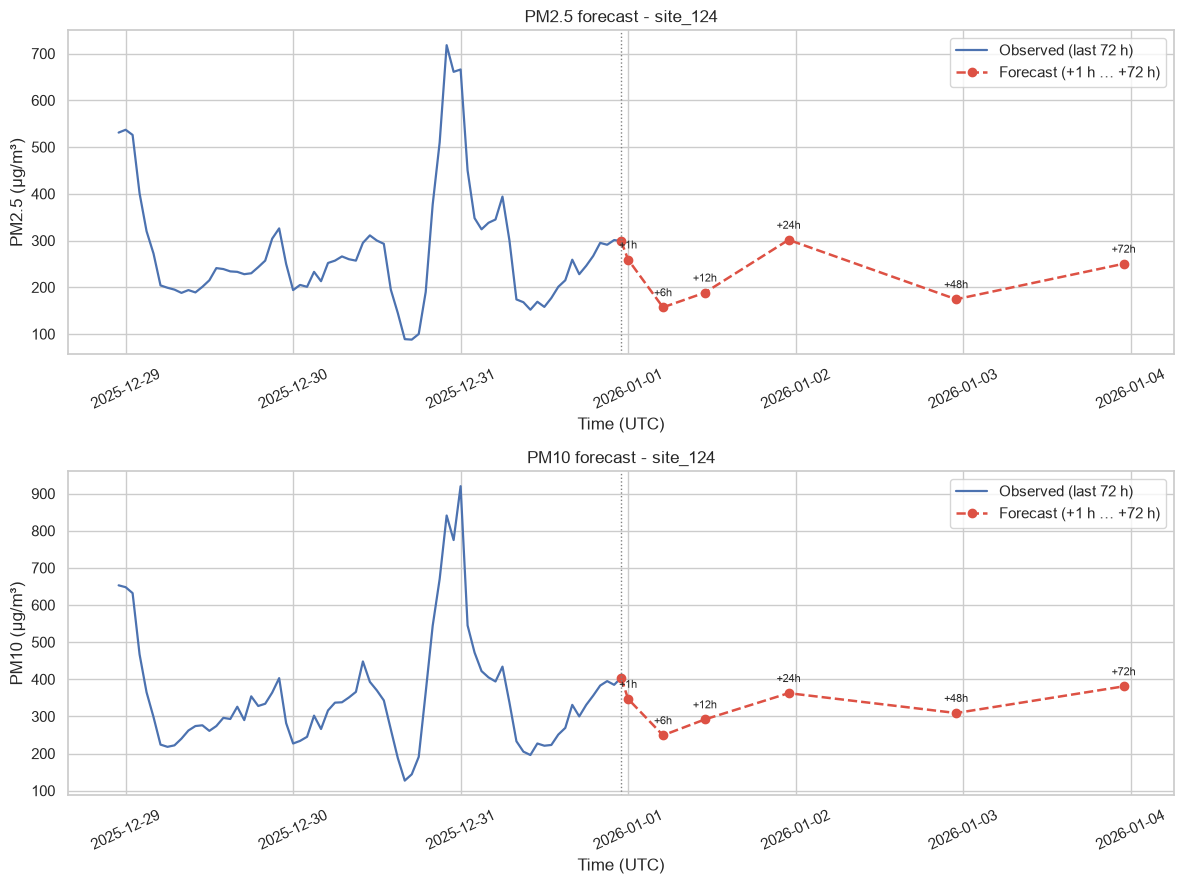

In [14]:
def plot_pollutant_forecast(key, ax, history_hours=72):
    col = POLLUTANTS[key]
    lo = max(int(station_pos[0]), origin_pos - history_hours)
    hist = df.iloc[lo:origin_pos + 1]
    fc = forecast_df[forecast_df["Pollutant"] == POLLUTANT_LABEL[key]].sort_values("Horizon")
    ax.plot(hist[TIME_COL], hist[col], color="#4c72b0", lw=1.6, label=f"Observed (last {history_hours} h)")
    x = [origin_ts] + fc["Forecast_Time"].tolist()
    y = [df[col].iloc[origin_pos]] + fc["Predicted_Concentration"].tolist()
    ax.plot(x, y, "--o", color="#dd5144", lw=1.8, ms=6, label="Forecast (+1 h … +72 h)")
    for t, v, h in zip(fc["Forecast_Time"], fc["Predicted_Concentration"], fc["Horizon"]):
        ax.annotate(f"+{h}h", (t, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    ax.axvline(origin_ts, color="grey", ls=":", lw=1)
    ax.set_title(f"{POLLUTANT_LABEL[key]} forecast - {STATION_NAME}")
    ax.set_xlabel("Time (UTC)"); ax.set_ylabel(f"{POLLUTANT_LABEL[key]} ({POLLUTANT_UNIT[key]})")
    ax.legend(loc="best"); ax.tick_params(axis="x", rotation=25)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
plot_pollutant_forecast("PM25", axes[0])
plot_pollutant_forecast("PM10", axes[1])
plt.tight_layout()
plt.savefig(FIGURE_DIR / "pm25_pm10_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

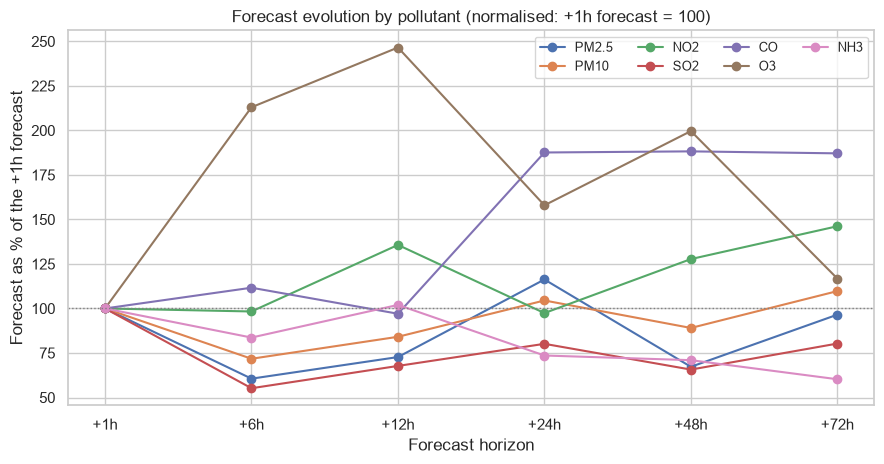

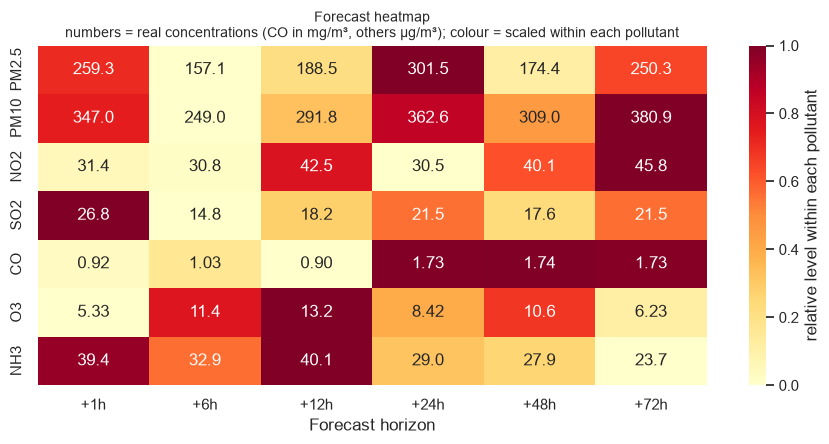

In [15]:
# 3. combined comparison: every pollutant relative to its own +1h forecast (=100), so different units are comparable
rel = forecast_pivot.div(forecast_pivot["+1h"].replace(0, np.nan), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
for pol in rel.index:
    ax.plot(rel.columns, rel.loc[pol], marker="o", label=pol)
ax.axhline(100, color="grey", ls=":", lw=1)
ax.set_title("Forecast evolution by pollutant (normalised: +1h forecast = 100)")
ax.set_xlabel("Forecast horizon"); ax.set_ylabel("Forecast as % of the +1h forecast")
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "pollutant_forecast_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. heatmap: colour = per-pollutant min-max scaling (comparable across rows), numbers = real concentrations
rng = forecast_pivot.max(axis=1) - forecast_pivot.min(axis=1)
scaled = forecast_pivot.sub(forecast_pivot.min(axis=1), axis=0).div(rng.replace(0, np.nan), axis=0).fillna(0.5)
labels = forecast_pivot.map(lambda v: f"{v:.2f}" if v < 10 else f"{v:.1f}")
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.heatmap(scaled, annot=labels, fmt="", cmap="YlOrRd", cbar_kws={"label": "relative level within each pollutant"}, ax=ax)
ax.set_title("Forecast heatmap\nnumbers = real concentrations (CO in mg/m³, others µg/m³); colour = scaled within each pollutant", fontsize=10)
ax.set_xlabel("Forecast horizon"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "forecast_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. CPCB AQI Calculation

AQI is **derived from the forecast concentrations**; no AQI model is trained or used.

```
predicted concentration  →  pollutant sub-index  →  AQI = max(sub-indices)  →  category
```

**Sub-index** (CPCB method, linear interpolation inside a breakpoint band):
`I = (I_hi − I_lo) / (BP_hi − BP_lo) × (C − BP_lo) + I_lo`

**Rules applied explicitly**

* **Valid AQI** needs at least **3 pollutants** with a sub-index, **one of which is PM2.5 or PM10**; otherwise the AQI is reported as *Insufficient data*.
* A concentration falling in the small gap between two bands (e.g. 30 – 31 µg/m³) takes the lower edge of the next band.
* CPCB leaves the top ("Severe") band open-ended. Here it is scaled with the width of the band below it and **capped at 500**.
* **Averaging caveat.** Official CPCB AQI uses **24-hour averages** (PM2.5, PM10, NO2, SO2, NH3) and **8-hour maximum moving averages** (CO, O3). The models forecast the concentration *at one specific hour*, and six sparse horizons cannot be turned into a 24 h or 8 h average without inventing values. The AQI below is therefore an **indicative forecast AQI**: CPCB breakpoints applied to the forecast hourly concentration. It is comparable across horizons but is not an official CPCB bulletin value.

In [16]:
# CPCB breakpoint bands: (concentration low, concentration high, sub-index low, sub-index high)
# Units: µg/m³ except CO in mg/m³.  hi = None marks the open-ended top band.
AQI_BREAKPOINTS = {
    "PM25": [(0, 30, 0, 50), (31, 60, 51, 100), (61, 90, 101, 200), (91, 120, 201, 300), (121, 250, 301, 400), (251, None, 401, 500)],
    "PM10": [(0, 50, 0, 50), (51, 100, 51, 100), (101, 250, 101, 200), (251, 350, 201, 300), (351, 430, 301, 400), (431, None, 401, 500)],
    "NO2":  [(0, 40, 0, 50), (41, 80, 51, 100), (81, 180, 101, 200), (181, 280, 201, 300), (281, 400, 301, 400), (401, None, 401, 500)],
    "SO2":  [(0, 40, 0, 50), (41, 80, 51, 100), (81, 380, 101, 200), (381, 800, 201, 300), (801, 1600, 301, 400), (1601, None, 401, 500)],
    "CO":   [(0, 1.0, 0, 50), (1.1, 2.0, 51, 100), (2.1, 10, 101, 200), (10.1, 17, 201, 300), (17.1, 34, 301, 400), (34.1, None, 401, 500)],
    "O3":   [(0, 50, 0, 50), (51, 100, 51, 100), (101, 168, 101, 200), (169, 208, 201, 300), (209, 748, 301, 400), (749, None, 401, 500)],
    "NH3":  [(0, 200, 0, 50), (201, 400, 51, 100), (401, 800, 101, 200), (801, 1200, 201, 300), (1201, 1800, 301, 400), (1801, None, 401, 500)],
}
AVERAGING_RULE = {"PM25": "24 h average", "PM10": "24 h average", "NO2": "24 h average", "SO2": "24 h average",
                  "NH3": "24 h average", "CO": "8 h max moving average", "O3": "8 h max moving average"}
AQI_CATEGORIES = [(50, "Good"), (100, "Satisfactory"), (200, "Moderately Polluted"), (300, "Poor"), (400, "Very Poor"), (500, "Severe")]
AQI_COLORS = {"Good": "#009865", "Satisfactory": "#98c13a", "Moderately Polluted": "#f0c419",
              "Poor": "#f08a1c", "Very Poor": "#e0452c", "Severe": "#8b1a1a", "Insufficient data": "#9e9e9e"}
AQI_BASIS = "indicative: CPCB breakpoints applied to the forecast hourly concentration"

def sub_index(key, concentration):
    """CPCB sub-index (0-500) for one pollutant concentration; NaN if the value is missing/invalid."""
    if concentration is None or not np.isfinite(concentration) or concentration < 0:
        return np.nan
    bands = AQI_BREAKPOINTS[key]
    for i, (lo, hi, i_lo, i_hi) in enumerate(bands):
        if hi is None:                                          # open-ended top band
            width = bands[i - 1][1] - bands[i - 1][0]
            return float(min(500.0, i_lo + (i_hi - i_lo) * (max(concentration, lo) - lo) / width))
        if concentration <= hi:
            return float(i_lo + (i_hi - i_lo) / (hi - lo) * (max(concentration, lo) - lo))
    return 500.0

def aqi_category(aqi):
    if aqi is None or not np.isfinite(aqi):
        return "Insufficient data"
    return next(name for limit, name in AQI_CATEGORIES if aqi <= limit)

def compute_aqi(sub_indices):
    """sub_indices: {pollutant key: sub-index}. Returns (AQI, category, dominant pollutant key)."""
    valid = {k: v for k, v in sub_indices.items() if np.isfinite(v)}
    if len(valid) < 3 or not ({"PM25", "PM10"} & set(valid)):
        return np.nan, "Insufficient data", None
    dominant = max(valid, key=valid.get)
    return float(valid[dominant]), aqi_category(valid[dominant]), dominant

# documentation table
bp_table = pd.DataFrame([
    {"Pollutant": POLLUTANT_LABEL[k], "Unit": POLLUTANT_UNIT[k], "Averaging (CPCB)": AVERAGING_RULE[k],
     **{name: (f"{lo}-{hi}" if hi is not None else f"{lo}+") for (lo, hi, _, _), (_, name) in zip(AQI_BREAKPOINTS[k], AQI_CATEGORIES)}}
    for k in POLLUTANTS])
display(bp_table)

# sub-indices for every forecast (pollutant x horizon) - computed from the PREDICTED concentrations
forecast_df["Sub_Index"] = [sub_index(LABEL_TO_KEY[p], c) for p, c in zip(forecast_df["Pollutant"], forecast_df["Predicted_Concentration"])]
subindex_pivot = forecast_df.pivot(index="Pollutant", columns="Horizon", values="Sub_Index").loc[list(order)]
print("Forecast sub-indices (pollutant x horizon):")
display(subindex_pivot.round(0).rename(columns=lambda h: f"+{h}h"))

# sanity checks of the implementation on band edges
assert sub_index("PM25", 30) == 50 and sub_index("PM25", 60) == 100 and sub_index("PM10", 100) == 100
assert sub_index("CO", 2.0) == 100 and sub_index("PM25", 1000) == 500
assert aqi_category(50) == "Good" and aqi_category(201) == "Poor" and aqi_category(450) == "Severe"

,Pollutant,Unit,Averaging (CPCB),Good,Satisfactory,Moderately Polluted,Poor,Very Poor,Severe
0,PM2.5,µg/m³,24 h average,0-30,31-60,61-90,91-120,121-250,251+
1,PM10,µg/m³,24 h average,0-50,51-100,101-250,251-350,351-430,431+
2,NO2,µg/m³,24 h average,0-40,41-80,81-180,181-280,281-400,401+
3,SO2,µg/m³,24 h average,0-40,41-80,81-380,381-800,801-1600,1601+
4,CO,mg/m³,8 h max moving average,0-1.0,1.1-2.0,2.1-10,10.1-17,17.1-34,34.1+
5,O3,µg/m³,8 h max moving average,0-50,51-100,101-168,169-208,209-748,749+
6,NH3,µg/m³,24 h average,0-200,201-400,401-800,801-1200,1201-1800,1801+


Forecast sub-indices (pollutant x horizon):


Horizon,+1h,+6h,+12h,+24h,+48h,+72h
Pollutant,,,,,,
PM2.5,407.0,329.0,353.0,440.0,342.0,401.0
PM10,297.0,199.0,242.0,316.0,259.0,338.0
NO2,39.0,39.0,53.0,38.0,51.0,57.0
SO2,34.0,18.0,23.0,27.0,22.0,27.0
CO,46.0,51.0,45.0,85.0,86.0,85.0
O3,5.0,11.0,13.0,8.0,11.0,6.0
NH3,10.0,8.0,10.0,7.0,7.0,6.0


## 14. Forecasted AQI by Horizon

For each horizon the AQI is the **highest pollutant sub-index** at that horizon, together with its category and the pollutant responsible (the dominant pollutant). The *Now* row applies the same method to the latest observed concentrations, as a reference point.

Reference - AQI from latest observed concentrations (2025-12-31 23:00 UTC): 438 (Severe), dominant PM2.5


,Horizon,Forecast_Time,AQI,Category,Dominant_Pollutant
0,+1h,2026-01-01 00:00:00+00:00,407,Severe,PM2.5
1,+6h,2026-01-01 05:00:00+00:00,329,Very Poor,PM2.5
2,+12h,2026-01-01 11:00:00+00:00,353,Very Poor,PM2.5
3,+24h,2026-01-01 23:00:00+00:00,440,Severe,PM2.5
4,+48h,2026-01-02 23:00:00+00:00,342,Very Poor,PM2.5
5,+72h,2026-01-03 23:00:00+00:00,401,Severe,PM2.5


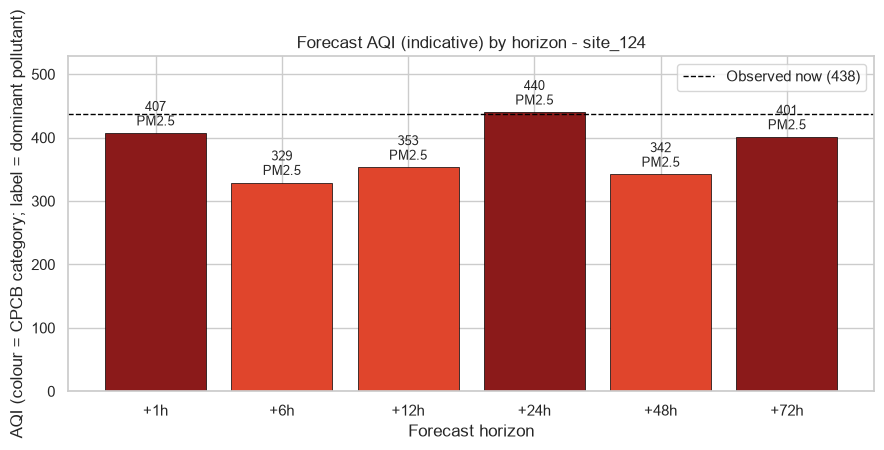

In [17]:
rows = []
for h in HORIZONS:
    aqi, cat, dom = compute_aqi({LABEL_TO_KEY[p]: subindex_pivot.loc[p, h] for p in subindex_pivot.index})
    rows.append({"Horizon": f"+{h}h", "Horizon_h": h, "Forecast_Time": origin_ts + pd.Timedelta(hours=h),
                 "AQI": round(aqi) if np.isfinite(aqi) else np.nan, "Category": cat,
                 "Dominant_Pollutant": POLLUTANT_LABEL[dom] if dom else "n/a", "Basis": AQI_BASIS})
aqi_forecast_df = pd.DataFrame(rows)
assert len(aqi_forecast_df) == len(HORIZONS)

now_aqi, now_cat, now_dom = compute_aqi({k: sub_index(k, current_values[k]) for k in POLLUTANTS})
print(f"Reference - AQI from latest observed concentrations ({origin_ts:%Y-%m-%d %H:%M} UTC): "
      f"{now_aqi:.0f} ({now_cat}), dominant {POLLUTANT_LABEL.get(now_dom, 'n/a')}" if np.isfinite(now_aqi)
      else "Reference - observed AQI could not be computed (insufficient current observations).")
display(aqi_forecast_df.drop(columns=["Horizon_h", "Basis"]))

fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [AQI_COLORS[c] for c in aqi_forecast_df["Category"]]
bars = ax.bar(aqi_forecast_df["Horizon"], aqi_forecast_df["AQI"], color=colors, edgecolor="black", lw=0.5)
for bar, (_, r) in zip(bars, aqi_forecast_df.iterrows()):
    if np.isfinite(r["AQI"]):
        ax.annotate(f"{int(r['AQI'])}\n{r['Dominant_Pollutant']}", (bar.get_x() + bar.get_width() / 2, r["AQI"]),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
if np.isfinite(now_aqi):
    ax.axhline(now_aqi, color="black", ls="--", lw=1, label=f"Observed now ({now_aqi:.0f})")
    ax.legend()
ax.set_ylim(0, max(100, np.nanmax(aqi_forecast_df["AQI"].to_numpy(dtype=float)) * 1.2))
ax.set_title(f"Forecast AQI (indicative) by horizon - {STATION_NAME}")
ax.set_xlabel("Forecast horizon"); ax.set_ylabel("AQI (colour = CPCB category; label = dominant pollutant)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "forecast_aqi_by_horizon.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Dominant Pollutant Analysis

At each horizon the dominant pollutant is the one with the **highest sub-index**. The table also shows the runner-up and the margin, so a close call (small margin) is distinguishable from a clear one.

,Horizon,Dominant,Dominant_Sub_Index,Runner_Up,Runner_Up_Sub_Index,Margin
0,+1h,PM2.5,407.3,PM10,297.0,110.3
1,+6h,PM2.5,328.7,PM10,199.3,129.3
2,+12h,PM2.5,352.8,PM10,241.8,111.0
3,+24h,PM2.5,439.7,PM10,315.5,124.2
4,+48h,PM2.5,341.9,PM10,259.0,82.9
5,+72h,PM2.5,401.0,PM10,338.4,62.6


+1h: PM2.5 -> +6h: PM2.5 -> +12h: PM2.5 -> +24h: PM2.5 -> +48h: PM2.5 -> +72h: PM2.5
Most frequent dominant pollutant across horizons: PM2.5 (6 of 6)
The same pollutant dominates at every horizon.


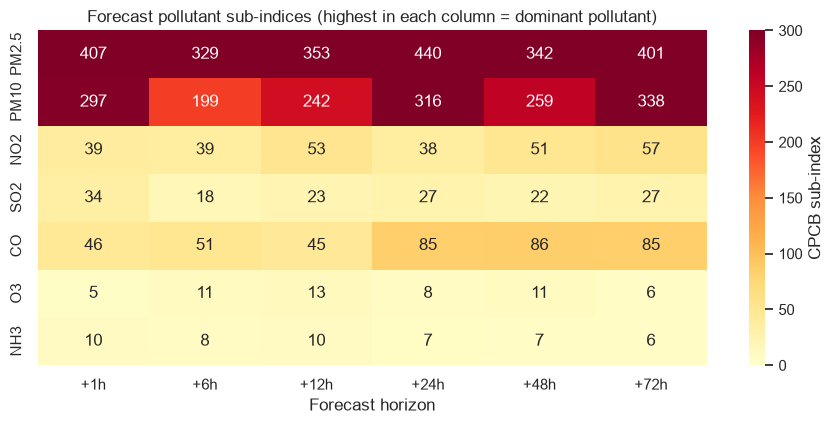

In [18]:
dom_rows = []
for h in HORIZONS:
    s = subindex_pivot[h].dropna().sort_values(ascending=False)
    dom_rows.append({
        "Horizon": f"+{h}h",
        "Dominant": s.index[0] if len(s) else "n/a",
        "Dominant_Sub_Index": round(s.iloc[0], 1) if len(s) else np.nan,
        "Runner_Up": s.index[1] if len(s) > 1 else "n/a",
        "Runner_Up_Sub_Index": round(s.iloc[1], 1) if len(s) > 1 else np.nan,
        "Margin": round(s.iloc[0] - s.iloc[1], 1) if len(s) > 1 else np.nan,
    })
dominant_df = pd.DataFrame(dom_rows)
display(dominant_df)

seq = " -> ".join(f"{r.Horizon}: {r.Dominant}" for r in dominant_df.itertuples())
print(seq)
counts = dominant_df["Dominant"].value_counts()
print(f"Most frequent dominant pollutant across horizons: {counts.index[0]} ({counts.iloc[0]} of {len(dominant_df)})")
print("Dominant pollutant changes over the horizon." if dominant_df["Dominant"].nunique() > 1
      else "The same pollutant dominates at every horizon.")

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.heatmap(subindex_pivot.rename(columns=lambda h: f"+{h}h"), annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=300,
            cbar_kws={"label": "CPCB sub-index"}, ax=ax)
ax.set_title("Forecast pollutant sub-indices (highest in each column = dominant pollutant)")
ax.set_xlabel("Forecast horizon"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "subindex_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 16. Pollutant Trend Analysis

For each pollutant the **+1 h forecast is compared with the +72 h forecast**:

`Change_Percentage = (F₊₇₂ₕ − F₊₁ₕ) / F₊₁ₕ × 100`

A change within **±`TREND_TOLERANCE_PCT`** (Section 2, default 5 %) is labelled *Approximately stable*. The latest **observed** concentration is also compared with the +72 h forecast as a second view. This is a descriptive indicator derived from the model outputs, not an additional model.

,Pollutant,Unit,Current,+1h,+72h,Change,Change_Percentage,Trend,Change_vs_Current_%,Trend_vs_Current
0,PM2.5,µg/m³,299.00,259.27,250.27,-9.00,-3.47,Approximately stable,-16.30,Decreasing
1,PM10,µg/m³,404.00,347.00,380.85,33.85,9.76,Increasing,-5.73,Decreasing
2,NO2,µg/m³,37.38,31.36,45.84,14.48,46.18,Increasing,22.64,Increasing
3,SO2,µg/m³,24.30,26.81,21.52,-5.28,-19.70,Decreasing,-11.43,Decreasing
4,CO,mg/m³,1.02,0.92,1.73,0.80,87.11,Increasing,69.01,Increasing
5,O3,µg/m³,0.97,5.33,6.23,0.90,16.78,Increasing,544.35,Increasing
6,NH3,µg/m³,36.45,39.36,23.72,-15.64,-39.75,Decreasing,-34.94,Decreasing


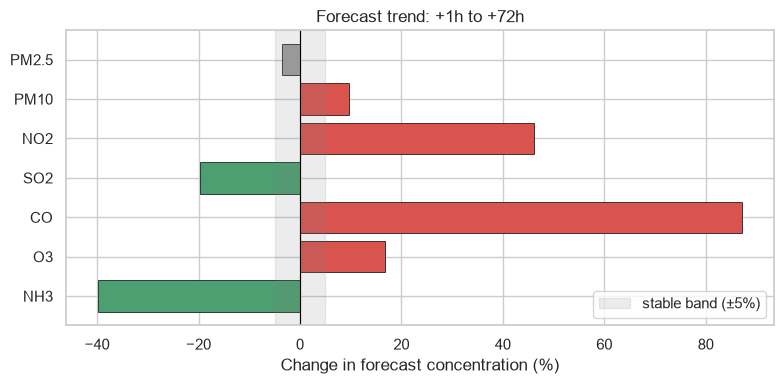

In [19]:
def classify_trend(pct):
    if not np.isfinite(pct):
        return "Undefined (zero baseline)"
    if abs(pct) <= TREND_TOLERANCE_PCT:
        return "Approximately stable"
    return "Increasing" if pct > 0 else "Decreasing"

trend_rows = []
for key in POLLUTANTS:
    lab = POLLUTANT_LABEL[key]
    f1, f72, cur = forecast_pivot.loc[lab, "+1h"], forecast_pivot.loc[lab, "+72h"], current_values[key]
    pct = (f72 - f1) / f1 * 100 if f1 > 0 else np.nan
    pct_cur = (f72 - cur) / cur * 100 if np.isfinite(cur) and cur > 0 else np.nan
    trend_rows.append({"Pollutant": lab, "Unit": POLLUTANT_UNIT[key], "Current": cur, "+1h": f1, "+72h": f72,
                       "Change": f72 - f1, "Change_Percentage": pct, "Trend": classify_trend(pct),
                       "Change_vs_Current_%": pct_cur, "Trend_vs_Current": classify_trend(pct_cur)})
trend_df = pd.DataFrame(trend_rows)
display(trend_df.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
colors = trend_df["Trend"].map({"Increasing": "#d9534f", "Decreasing": "#4c9f70", "Approximately stable": "#9e9e9e"}).fillna("#cccccc")
ax.barh(trend_df["Pollutant"], trend_df["Change_Percentage"].fillna(0), color=colors, edgecolor="black", lw=0.5)
ax.axvline(0, color="black", lw=0.8)
ax.axvspan(-TREND_TOLERANCE_PCT, TREND_TOLERANCE_PCT, color="grey", alpha=0.15, label=f"stable band (±{TREND_TOLERANCE_PCT:g}%)")
ax.invert_yaxis(); ax.legend(loc="lower right")
ax.set_title("Forecast trend: +1h to +72h"); ax.set_xlabel("Change in forecast concentration (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "pollutant_trends.png", dpi=150, bbox_inches="tight")
plt.show()

## 17. Final Forecast Summary

In [20]:
def fmt(v):
    return f"{v:,.2f}" if v < 10 else f"{v:,.1f}"

line = "=" * 60
print(line); print("AEROCAST FORECAST SUMMARY"); print(line)
print(f"\nStation:\n  {STATION_ID} - {STATION_NAME}")
print(f"\nForecast origin:\n  {origin_ts:%Y-%m-%d %H:%M} UTC")
print("\n72-hour forecast (concentration at +1h / +6h / +12h / +24h / +48h / +72h):")
for p in forecast_pivot.index:
    vals = " | ".join(fmt(v) for v in forecast_pivot.loc[p])
    print(f"  {p:<6}: {vals}   {POLLUTANT_UNIT[LABEL_TO_KEY[p]]}")
print(f"\nForecast AQI ({AQI_BASIS}):")
for r in aqi_forecast_df.itertuples():
    val = f"{int(r.AQI)}" if np.isfinite(r.AQI) else "n/a"
    print(f"  {r.Horizon:<5}: {val:>4}  {r.Category:<20} dominant: {r.Dominant_Pollutant}")
top = dominant_df["Dominant"].value_counts()
print(f"\nDominant pollutant:\n  {top.index[0]} at {top.iloc[0]} of {len(dominant_df)} horizons ({seq})")
pm = trend_df[trend_df["Pollutant"] == "PM2.5"].iloc[0]
print(f"\nOverall PM2.5 trend:\n  {pm['Trend']} ({pm['Change_Percentage']:+.1f}% from +1h to +72h)" if np.isfinite(pm["Change_Percentage"])
      else "\nOverall PM2.5 trend:\n  undefined (zero +1h forecast)")
print("\n" + line)

AEROCAST FORECAST SUMMARY

Station:
  site_124 - site_124

Forecast origin:
  2025-12-31 23:00 UTC

72-hour forecast (concentration at +1h / +6h / +12h / +24h / +48h / +72h):
  PM2.5 : 259.3 | 157.1 | 188.5 | 301.5 | 174.4 | 250.3   µg/m³
  PM10  : 347.0 | 249.0 | 291.8 | 362.6 | 309.0 | 380.9   µg/m³
  NO2   : 31.4 | 30.8 | 42.5 | 30.5 | 40.1 | 45.8   µg/m³
  SO2   : 26.8 | 14.8 | 18.2 | 21.5 | 17.6 | 21.5   µg/m³
  CO    : 0.92 | 1.03 | 0.90 | 1.73 | 1.74 | 1.73   mg/m³
  O3    : 5.33 | 11.4 | 13.2 | 8.42 | 10.6 | 6.23   µg/m³
  NH3   : 39.4 | 32.9 | 40.1 | 29.0 | 27.9 | 23.7   µg/m³

Forecast AQI (indicative: CPCB breakpoints applied to the forecast hourly concentration):
  +1h  :  407  Severe               dominant: PM2.5
  +6h  :  329  Very Poor            dominant: PM2.5
  +12h :  353  Very Poor            dominant: PM2.5
  +24h :  440  Severe               dominant: PM2.5
  +48h :  342  Very Poor            dominant: PM2.5
  +72h :  401  Severe               dominant: PM2.5

Dom

## 18. Export Results

Results go to `../evaluation/`. The model files are not touched; the cell finishes with an integrity check on them.

In [21]:
EXPORTS = {
    "aerocast_forecast_results.csv": forecast_df.drop(columns=["Sub_Index"]),
    "aerocast_aqi_forecast.csv": aqi_forecast_df.drop(columns=["Horizon_h"]),
    "aerocast_trend_analysis.csv": trend_df,
}
for fname, frame in EXPORTS.items():
    frame.to_csv(EVALUATION_DIR / fname, index=False)
    print(f"saved {EVALUATION_DIR / fname}   ({len(frame)} rows)")

# ---- final integrity checks ------------------------------------------------------------------------------------
assert len(forecast_df) == 42 and forecast_df["Predicted_Concentration"].notna().all()
assert all((EVALUATION_DIR / f).exists() for f in EXPORTS)
unchanged = all((MODEL_PATHS[n].stat().st_size, MODEL_PATHS[n].stat().st_mtime_ns) == file_snapshot[n] for n in file_snapshot)
assert unchanged, "A model file changed while the notebook was running!"

print("\nIntegrity checks")
print("  [OK] 42 models found, loaded and compatible; none retrained")
print("  [OK] 42 forecasts generated, all finite")
print("  [OK] AQI derived from the predicted concentrations")
print(f"  [OK] model files unchanged (size + modification time of all {len(file_snapshot)} files)")
print("  [OK] CSV exports written to", EVALUATION_DIR)

saved ..\evaluation\aerocast_forecast_results.csv   (42 rows)
saved ..\evaluation\aerocast_aqi_forecast.csv   (6 rows)
saved ..\evaluation\aerocast_trend_analysis.csv   (7 rows)

Integrity checks
  [OK] 42 models found, loaded and compatible; none retrained
  [OK] 42 forecasts generated, all finite
  [OK] AQI derived from the predicted concentrations
  [OK] model files unchanged (size + modification time of all 42 files)
  [OK] CSV exports written to ..\evaluation


## Appendix A. Optional: Historical Inference Comparison

The models are already trained, so this appendix only **runs them on past data and compares the forecasts with what was actually measured** (MAE, RMSE, R²). It never trains anything.

**How to read these numbers.** The model files do not record their training period. The training setup supplied with the models used 2021–2023 for fitting, 2024 for validation and 2025 as the test period, so `HELD_OUT_START` defaults to 2025-01-01. Because this cannot be verified from the JSON files themselves, the results are reported as a **historical inference comparison**, not as a certified held-out test evaluation. Origins are sampled every `EVAL_STRIDE_HOURS` hours across all stations; the "actual" value is the same station's measurement `h` hours later (a *target*, never an input). The persistence baseline ("the future equals the current value") is included for context.

In [22]:
# ---- A.1 the forecast just made vs the actual measurements (only possible if the later hours exist) ----------------
actual_rows = []
for r in forecast_df.itertuples():
    key = LABEL_TO_KEY[r.Pollutant]
    tpos = origin_pos + r.Horizon
    ok = tpos < len(df) and df[ID_COL].iloc[tpos] == STATION_ID and df[TIME_COL].iloc[tpos] == r.Forecast_Time
    actual = df[POLLUTANTS[key]].iloc[tpos] if ok else np.nan
    actual_rows.append({"Pollutant": r.Pollutant, "Horizon": f"+{r.Horizon}h", "Predicted": r.Predicted_Concentration,
                        "Actual": actual, "Abs_Error": abs(r.Predicted_Concentration - actual) if pd.notna(actual) else np.nan})
selected_origin_check = pd.DataFrame(actual_rows)
if selected_origin_check["Actual"].notna().any():
    print(f"Selected forecast (origin {origin_ts}) vs measured values:")
    display(selected_origin_check.pivot(index="Pollutant", columns="Horizon", values="Abs_Error")
            .loc[list(order), [f"+{h}h" for h in HORIZONS]].round(2).rename_axis(columns="Absolute error"))
else:
    print("No measurements exist after the selected origin (it is the latest data), so there is nothing to compare against. "
          "Set FORECAST_TIME to an earlier hour to compare a single forecast with reality.")

No measurements exist after the selected origin (it is the latest data), so there is nothing to compare against. Set FORECAST_TIME to an earlier hour to compare a single forecast with reality.


Historical inference comparison: 21,900 forecast origins from 2025-01-01 (15 stations, every 6 h)


R² (inference comparison),+1h,+6h,+12h,+24h,+48h,+72h
pollutant,,,,,,
PM2.5,0.925,0.756,0.683,0.679,0.596,0.558
PM10,0.866,0.669,0.588,0.585,0.463,0.414
NO2,0.917,0.683,0.603,0.677,0.613,0.575
SO2,0.788,0.350,0.248,0.354,0.252,0.196
CO,0.845,0.493,0.397,0.469,0.374,0.341
O3,0.931,0.677,0.616,0.751,0.700,0.678
NH3,0.929,0.748,0.668,0.712,0.602,0.513


Average by horizon:


,MAE,RMSE,R2
horizon,,,
1,9.008,15.685,0.886
6,17.399,26.822,0.625
12,19.895,30.018,0.543
24,19.258,28.907,0.604
48,22.059,32.513,0.514
72,23.098,34.005,0.468


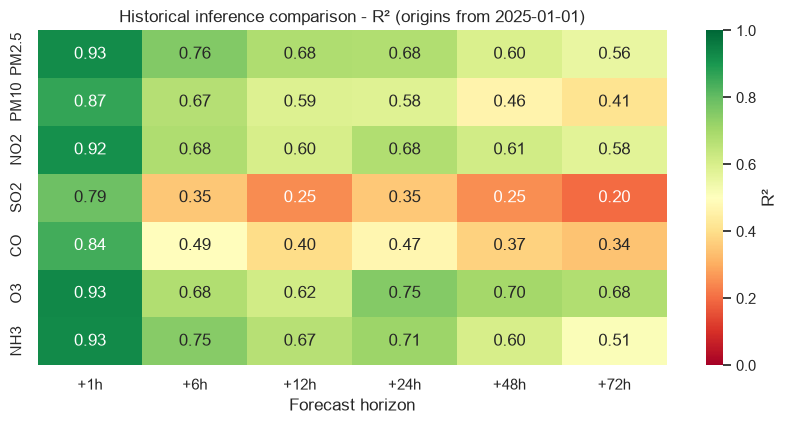

Saved: ..\evaluation\aerocast_historical_inference_comparison.csv


In [23]:
if not RUN_HISTORICAL_COMPARISON:
    print("RUN_HISTORICAL_COMPARISON is False - skipping.")
else:
    start = pd.Timestamp(HELD_OUT_START)
    start = start.tz_localize("UTC") if start.tzinfo is None else start.tz_convert("UTC")
    mask = (df[TIME_COL] >= start).to_numpy() & ((df[TIME_COL].dt.hour % EVAL_STRIDE_HOURS) == 0).to_numpy()
    eval_pos = np.flatnonzero(mask)
    if len(eval_pos) == 0:
        raise ValueError(f"No rows on/after {start}. Change HELD_OUT_START.")
    X_eval = feature_frame(eval_pos, all_feed_names)
    print(f"Historical inference comparison: {len(eval_pos):,} forecast origins from {start:%Y-%m-%d} "
          f"({df[ID_COL].iloc[eval_pos].nunique()} stations, every {EVAL_STRIDE_HOURS} h)")

    rows = []
    for key, col in POLLUTANTS.items():
        by_station = df.groupby(ID_COL, sort=False)[col]
        current = df[col].to_numpy(dtype="float64")[eval_pos]
        for h in HORIZONS:
            name = f"{key}_{h}h"
            y = by_station.shift(-h).to_numpy(dtype="float64")[eval_pos]      # actual future value, same station
            pred = predict_concentration(models[name], X_eval[feed_columns[name]])
            ok = np.isfinite(y)
            m_ok = ok & np.isfinite(current)
            mae = mean_absolute_error(y[ok], pred[ok])
            rows.append({"model": name, "pollutant": POLLUTANT_LABEL[key], "horizon": h, "n_eval": int(ok.sum()),
                         "MAE": mae, "RMSE": float(np.sqrt(mean_squared_error(y[ok], pred[ok]))), "R2": r2_score(y[ok], pred[ok]),
                         "persistence_MAE": mean_absolute_error(y[m_ok], current[m_ok]),
                         "MAE_gain_vs_persistence_%": (1 - mae / mean_absolute_error(y[m_ok], current[m_ok])) * 100})
    historical_comparison = pd.DataFrame(rows)
    historical_comparison.to_csv(EVALUATION_DIR / "aerocast_historical_inference_comparison.csv", index=False)
    assert len(historical_comparison) == 42

    display(historical_comparison.pivot(index="pollutant", columns="horizon", values="R2").loc[list(order)].round(3)
            .rename(columns=lambda h: f"+{h}h").rename_axis(columns="R² (inference comparison)"))
    print("Average by horizon:")
    display(historical_comparison.groupby("horizon")[["MAE", "RMSE", "R2"]].mean().round(3))

    r2 = historical_comparison.pivot(index="pollutant", columns="horizon", values="R2").loc[list(order)]
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    sns.heatmap(r2.rename(columns=lambda h: f"+{h}h"), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "R²"})
    ax.set_title(f"Historical inference comparison - R² (origins from {start:%Y-%m-%d})")
    ax.set_xlabel("Forecast horizon"); ax.set_ylabel("")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "historical_comparison_r2.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", EVALUATION_DIR / "aerocast_historical_inference_comparison.csv")